# 04 · The qlPCA algorithm

Sections 3.1–3.2 of the thesis [`lavado2012phd`], and the English account in [`lavado2011ijam`] (see also the shorter
[`lavado2011wce`]). This notebook states the objective, gives the **corrected pseudo-code** (the one printed in the thesis omits a
step that the MATLAB code performs), compares the **legacy** behaviour (the 2012 MATLAB code, which produced the thesis numbers) with the
**default** behaviour of this package (docs/DESIGN.md), and walks through the properties of the solution: variance accounted for,
scree plots, projection of new observations, reconstruction, piecewise loadings.

*Contents:* 1. diagram (thesis Fig. 3.1) · 2. objective · 3. corrected pseudo-code · 4. the algorithm at work ·
5. legacy versus default · 6. properties of the solution (scree plot = thesis Fig. 3.2) · 7. projection, reconstruction, piecewise loadings ·
8. from the MATLAB listings to the package · 9. ties and over-parametrisation · References.

In [1]:
import json, pathlib, sys, warnings, collections
import numpy as np
import matplotlib.pyplot as plt
from qlpca import QLPCA, pseudo_indicator
from qlpca.datasets import load_st_gender, make_cylinder
from qlpca.diagnostics import vaf, vaf_percent, communalities, piecewise_loadings
from qlpca.plots import set_style, algorithm_diagram, scree_plot, BLUE, ORANGE, INK, INK2, GRID

set_style()
np.set_printoptions(precision=3, suppress=True, linewidth=120)
X, names, countries = load_st_gender()
n, m = X.shape
ref = json.load(open(pathlib.Path("..") / "tests" / "reference_values.json", encoding="utf8"))

## 1 · Diagram (thesis Figure 3.1)

The algorithm has two phases that alternate until convergence: the update of the **quantifications** (the transformed variables
$f_j$) given the object scores, and the estimation of the **object scores** (and loadings) given the quantifications.

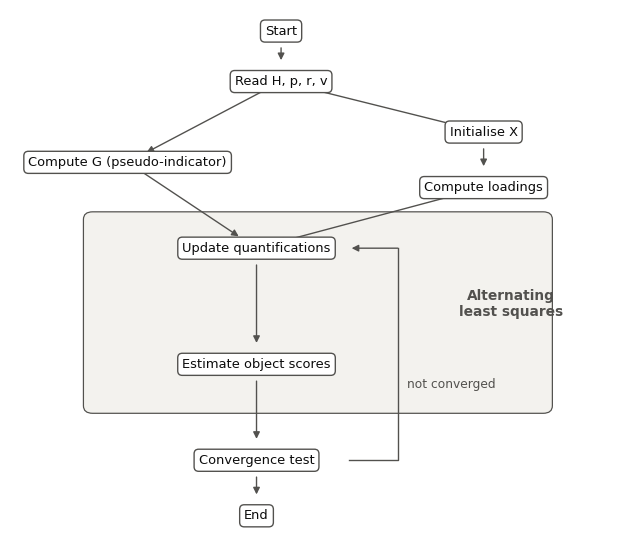

In [2]:
algorithm_diagram()
plt.show()

## 2 · Objective

Let $H$ be the $n\times m$ matrix of standardised data, $p$ the number of retained components, $v$ the spline degree and $r$ the number
of interior knots ($w=v+r$ I-splines per variable). All variables get the *Single* treatment (notebook 02), so the objective is

$$\sigma(X,F)=\frac1n\sum_{j=1}^{m}(Xa_j-f_j)'(Xa_j-f_j),\qquad X'X=nI,\qquad f_j=G_jy_j,$$

with $G_j$ the pseudo-indicator matrix of variable $j$ ($n\times w$) and $y_j$ the spline coefficients. The degree and the number
and location of knots are parameters of the model, not optimised: the problem is linear in the coefficients but highly nonlinear in
the knots [`winsberg1983monotone`].

## 3 · Corrected pseudo-code

Differences from the pseudo-code printed in thesis §3.1.3 (and in [`lavado2011ijam`, IV.B]) are in **bold**.

```text
Input   raw data (n x m), p, v, r
        H <- standardise columns (sample sd, ddof = 1)

I.   Initialisation
     1  Z <- linearPCA(H), p components;  [K, L, W] <- svd(Z);  X <- sqrt(n) K W'        (X'X = nI)
     2  a_j <- X' h_j / n                                         j = 1..m
     3  G_j <- createIspline(H, v, r)                             j = 1..m
        **G_j <- G_j with the column means removed (centred)**    <- missing in the printed code

II.  ALS: update of the quantifications          (loop over j)
     1  y~_j <- X a_j
     2  y_j  <- (G_j' G_j)^-1 G_j' y~_j            (**no 1/n factor: it only rescales y_j and step 5 removes it**)
     3  f_j  <- G_j y_j
     4  f_j  <- f_j - mean(f_j)
     5  f_j  <- sqrt(n) f_j / ||f_j||

III. ALS: update of the object scores and loadings
     1  F <- [f_1 ... f_m];   [U, S, V'] <- svd(F)
     2  **X <- sqrt(n) U_p ;   A <- V_p S_p / sqrt(n)**      (A = X'F/n at the optimum; row j of A is a_j')

IV.  Convergence
     loss <- m - sum_{s<=p} S_s^2 / n
     stop if |loss_k - loss_{k-1}| < 1e-6  or after max_iter iterations (warn if max_iter is hit)

Output  X (n x p), F (n x m), A (m x p), spline coefficients y_j
```

Why each change:

1. **Centring.** The I-splines span $w=v+r$ functions and *not* the constants. The regression in II.2 has no intercept, so unless the
   columns of $G_j$ are centred (equivalently: an intercept is added) the fit is far worse. The MATLAB code does this by `zscore(G)` —
   this step is absent from the printed pseudo-code but is part of the method. On the chapter 4 data the pseudo-code read literally gives
   $50.50$, $68.21$, $65.35$, $79.51\ \%$ VAF for $(r,p)=(1,2),(1,3),(2,2),(2,3)$, below the $61.89\ \%$ of ordinary PCA with two
   components, whereas with centring the figures are $68.90, 84.02, 76.33, 90.30$ (docs/SPEC.md §6; the literal-pseudo-code figures were
   obtained with the prototype in November 2026 and are not recomputed here, since the package always centres).
2. **III.** The printed step III does a linear PCA of $F$, and II.6 updates $a_j=X'f_j/n$ one variable at a time. The truncated SVD of
   $F$ gives the $(X,A)$ that minimise the loss jointly for the current $F$ (loss $=m-\sum_{s\le p}\lambda_s$ with $\lambda_s=S_s^2/n$), so the loss
   never increases (§4). The MATLAB listings do the same with an eigen-decomposition of $F'F$.
3. **Start values.** The printed pseudo-code starts from PCA scores (as above); the MATLAB code starts from the first $p$ columns of $G$. The package default
   uses the PCA start **plus several random orthonormal starts** and keeps the lowest loss (§5); `legacy=True` uses the MATLAB start.
4. **Convergence.** The thesis states a test on successive values of the loss against $0.1\times10^{-5}$; the MATLAB listing contains no such test
   (open question 1, docs/SPEC.md §9). The package tests the absolute change of the loss against `tol=1e-6`.

## 4 · The algorithm at work

For the chapter 4 data (notebook 06), the pseudo-indicator matrix of one variable with $r=2$ interior knots has $w=v+r=3$ columns, and
together with the constant it spans the same space as the four B-splines of the same knots — the default estimator uses that centred B-spline
basis (DESIGN D2).

In [3]:
H = (X - X.mean(0)) / X.std(0, ddof=1)
j = names.index("mf_funds")
G, kn = pseudo_indicator(H[:, j], 1, 2)
print("variable:", names[j], "| G shape (n x w):", G.shape, "| knot sequence:", np.round(kn, 2))
print("rank of G:", np.linalg.matrix_rank(G), "| rank of [1, G]:", np.linalg.matrix_rank(np.c_[np.ones(n), G]))

variable: mf_funds | G shape (n x w): (15, 3) | knot sequence: [-1.59 -1.59 -0.69  0.72  1.3   1.3 ]
rank of G: 3 | rank of [1, G]: 4


default: iterations  26 | loss 2.603932 | eigenvalues [4.759 3.637] | VAF 76.33 %
legacy : iterations  33 | loss 2.603933 | eigenvalues [4.759 3.637] | VAF 76.33 %
loss = m - (lambda_1 + lambda_2): True
loss never increases:  default True | legacy True


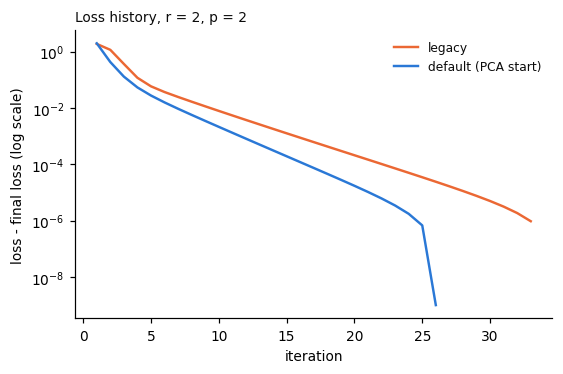

In [4]:
default = QLPCA(2, degree=1, n_knots=2, random_state=0).fit(X)
legacy = QLPCA(2, degree=1, n_knots=2, legacy=True).fit(X)

for label, mdl in (("default", default), ("legacy ", legacy)):
    print(f"{label}: iterations {mdl.n_iter_:3d} | loss {mdl.loss_:.6f} | eigenvalues {mdl.eigenvalues_} | "
          f"VAF {100 * mdl.eigenvalues_.sum() / m:.2f} %")
print("loss = m - (lambda_1 + lambda_2):", np.isclose(default.loss_, m - default.eigenvalues_.sum()))
print("loss never increases:  default", bool(np.all(np.diff(default.loss_history_) <= 1e-10)),
      "| legacy", bool(np.all(np.diff(legacy.loss_history_) <= 1e-10)))

fig, ax = plt.subplots(figsize=(5.6, 3.4))
floor = min(default.loss_, legacy.loss_) - 1e-9
for mdl, c, lab in ((legacy, ORANGE, "legacy"), (default, BLUE, "default (PCA start)")):
    ax.semilogy(np.arange(1, mdl.n_iter_ + 1), mdl.loss_history_ - floor, color=c, lw=1.6, label=lab)
ax.set_xlabel("iteration"); ax.set_ylabel("loss - final loss (log scale)")
ax.set_title("Loss history, r = 2, p = 2", loc="left", fontsize=9); ax.legend(fontsize=8)
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.show()

The loss decreases monotonically in both variants, and both stop when the change falls below $10^{-6}$.

## 5 · Legacy versus default

`legacy=True` reproduces the 2012 MATLAB behaviour: start from the first $p$ columns of the standardised $G$, eigen-decomposition update,
a single start, unique values required. The default is described in docs/DESIGN.md (D1–D10). With two components they agree; the
interesting differences are about **local optima**.

In [5]:
thesis_p2 = {1: ref["table_4_5_qlpca"]["qlpca1"]["total_pct"], 2: ref["table_4_5_qlpca"]["qlpca2"]["total_pct"]}
print("  r  p   legacy %VAF   default %VAF   thesis (Table 4.5)")
for r, p in [(1, 2), (2, 2), (1, 3), (2, 3)]:
    lg = QLPCA(p, n_knots=r, legacy=True).fit(X)
    df = QLPCA(p, n_knots=r, random_state=0).fit(X)
    t = f"{thesis_p2[r]:.2f}" if p == 2 else "—"
    print(f"  {r}  {p}   {100 * lg.eigenvalues_.sum() / m:11.2f}   {100 * df.eigenvalues_.sum() / m:12.2f}   {t}")

  r  p   legacy %VAF   default %VAF   thesis (Table 4.5)


  1  2         68.90          68.90   68.90


  2  2         76.33          76.33   76.33


  1  3         84.02          84.02   —


  2  3         90.00          90.30   —


For $r=2$, $p=3$ the legacy start reaches a different local optimum depending on the **order of the columns** of the data matrix (the first
$p$ columns of $G$ are basis functions of the first variable). The default result does not depend on the order. Twelve random permutations of the columns:

In [6]:
rng = np.random.default_rng(0)
leg, dft = collections.Counter(), collections.Counter()
for _ in range(12):
    perm = rng.permutation(m)
    leg[round(100 * QLPCA(3, n_knots=2, legacy=True).fit(X[:, perm]).eigenvalues_.sum() / m, 2)] += 1
    dft[round(100 * QLPCA(3, n_knots=2, random_state=0).fit(X[:, perm]).eigenvalues_.sum() / m, 2)] += 1
print("legacy  %VAF over 12 column orders:", {float(k): v for k, v in sorted(leg.items())})
print("default %VAF over 12 column orders:", {float(k): v for k, v in sorted(dft.items())})

legacy  %VAF over 12 column orders: {90.0: 6, 90.3: 6}
default %VAF over 12 column orders: {90.3: 12}


Different starts really do end in different optima, so a single start is not enough: the final losses of 40 random starts (plus the
PCA start) for $r=2$, $p=3$:

In [7]:
many = QLPCA(3, n_knots=2, n_init=40, random_state=0).fit(X)
vaf_starts = collections.Counter(np.round(100 * (m - many.losses_) / m, 2))
print("%VAF reached by the", len(many.losses_), "starts (first = PCA start):", {float(k): v for k, v in sorted(vaf_starts.items(), reverse=True)})
print("PCA start reaches   :", round(100 * (m - many.losses_[0]) / m, 2))
print("retained (lowest loss):", round(100 * many.eigenvalues_.sum() / m, 2))

%VAF reached by the 41 starts (first = PCA start): {90.3: 29, 90.0: 11, 89.74: 1}
PCA start reaches   : 90.3
retained (lowest loss): 90.3


Thesis Figure 4.5 (two interior knots, three components) shows one of these local optima; notebook 06 reports both.
The default keeps the one with the lowest loss, and the PCA start alone already finds it here.

## 6 · Properties of the solution (thesis §3.1.4)

**Variance accounted for.** $\mathrm{VAF}_s=\sum_j a_{sj}^2$ equals the $s$-th eigenvalue of the correlation matrix $R=F'F/n$ of the transformed
variables; the percentage is $\mathrm{VAF}_s\cdot100/m$. The **communality** of variable $j$ is $\sum_s a_{js}^2$ (the variance of the transformed
variable explained by the retained components; the usual rule keeps variables with communality $\ge0.25$). The percentages refer to the
*transformed* matrix and are not directly comparable with PCA's (notebook 02).

In [8]:
for key, r in (("qlpca1", 1), ("qlpca2", 2)):
    mdl = QLPCA(2, degree=1, n_knots=r, legacy=True).fit(X)
    t = ref["table_4_5_qlpca"][key]
    print(f"r={r}: eigenvalues {mdl.eigenvalues_}  (thesis {t['eigenvalues']}) | %VAF per dimension {vaf_percent(mdl.loadings_).round(2)} (thesis {t['pct_variance']})")
    print("      communalities  max |diff| to thesis Tables 4.7/4.8:",
          np.abs(communalities(mdl.loadings_) - ref["communalities"][key]).max().round(3))
    print("      |loadings|     max |diff| to thesis Table 4.6      :",
          np.abs(np.abs(mdl.loadings_) - np.abs(ref["table_4_6_loadings"][key])).max().round(3))

r=1: eigenvalues [4.582 2.998]  (thesis [4.582, 2.998]) | %VAF per dimension [41.65 27.25] (thesis [41.65, 27.25])
      communalities  max |diff| to thesis Tables 4.7/4.8: 0.005
      |loadings|     max |diff| to thesis Table 4.6      : 0.005
r=2: eigenvalues [4.759 3.637]  (thesis [4.76, 3.637]) | %VAF per dimension [43.27 33.06] (thesis [43.27, 33.06])
      communalities  max |diff| to thesis Tables 4.7/4.8: 0.003
      |loadings|     max |diff| to thesis Table 4.6      : 0.005


**Scree plot and the number of components.** The scree plot shows all the eigenvalues of $R$. The solutions for different $p$ are *not nested*
(the transformations change with $p$), so compare $p-1$, $p$ and $p+1$. The left panel regenerates the kind of figure in thesis Figure 3.2 — a
scree plot of a linear PCA with 12 variables — from the simulated cylinder data of section 3.3 (notebook 05); the random draws are not
those of the thesis. The right panel compares, on the chapter 4 data, the eigenvalues of the correlation matrix of the original and of the
transformed variables.

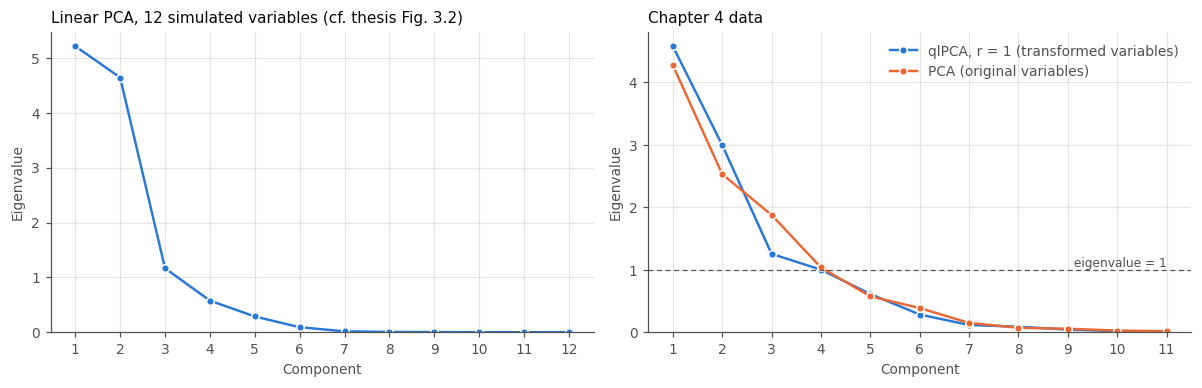

In [9]:
Xc, _ = make_cylinder(51, 0, random_state=0)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
scree_plot(np.linalg.eigvalsh(np.corrcoef(Xc.T))[::-1], ax=axes[0], kaiser=False,
           title="Linear PCA, 12 simulated variables (cf. thesis Fig. 3.2)")
ql = QLPCA(2, degree=1, n_knots=1, random_state=0).fit(X)
scree_plot(ql, ax=axes[1], label="qlPCA, r = 1 (transformed variables)",
           reference=np.linalg.eigvalsh(np.corrcoef(X.T))[::-1], reference_label="PCA (original variables)",
           title="Chapter 4 data")
plt.tight_layout(); plt.show()

## 7 · Projection, reconstruction, piecewise loadings (degree 1)

For splines of degree 1 the transformation of variable $j$ is a broken line through the points $(h_j,f_j)$ at the knots, so it can be evaluated outside
the sample by **linear interpolation** (and **linear extrapolation** beyond the range). A new observation is then projected on the nonlinear
components by $X_{\text{new}}=\sqrt n\,F_{\text{new}}A\,(A'F'FA)^{-1/2}$ — the form that returns the training scores exactly for the training rows
(the thesis's eq. 3.5 in another notation; DESIGN D10). Reconstruction inverts the broken lines: $\hat F=XA'$, then $\hat h_j=f_j^{-1}(\hat f_j)$.

In [10]:
mdl = QLPCA(2, degree=1, n_knots=1, random_state=0).fit(X)
print("projection of the training rows returns the training scores:", np.allclose(mdl.transform(X), mdl.scores_))

new = X.mean(0, keepdims=True).copy()                      # an "average" country...
new[0, names.index("investment")] = X[:, names.index("investment")].max() * 1.2   # ...with investment 20 % above the sample maximum
print("scores of the new observation:", mdl.transform(new).round(3), "(extrapolates the broken line for 'investment')")

projection of the training rows returns the training scores: True
scores of the new observation: [[0.035 0.21 ]] (extrapolates the broken line for 'investment')


**Reconstruction is exact only where the inverse of $f_j$ exists.** With all components retained ($p=m$), $XA'=F$ exactly, but $H$ can be recovered
only for variables whose transformation is strictly monotone; where $f_j$ turns back, several values of $h_j$ share one value of $f_j$ and the first matching segment is used.
(With `monotone=True` the constrained fit often contains flat segments, which have the same effect.)

In [11]:
full = QLPCA(m, degree=1, n_knots=1, random_state=0).fit(X)
print("X A' equals F when p = m:", np.allclose(full.scores_ @ full.loadings_.T, full.transformed_))
Hhat = full.inverse_transform(full.scores_)
print("variable            monotone f_j   max |reconstruction error|")
for j, nm in enumerate(names):
    f = full._curve(j)[1]
    mono = bool(np.all(np.diff(f) > 0) or np.all(np.diff(f) < 0))
    print(f"{nm:20s}  {str(mono):12s}   {np.abs(Hhat[:, j] - X[:, j]).max():10.4f}")
print("re-transforming the reconstruction returns F for every variable:",
      np.allclose(full.transform_variables(Hhat), full.transformed_, atol=1e-6))

X A' equals F when p = m: True
variable            monotone f_j   max |reconstruction error|
researchers           True               0.0000
scientists_engineers  True               0.0000
investment            True               0.0000
mf_funds              True               0.0000
w_top                 False              1.0101
m_top                 False              6.9680
glass_ceiling         True               0.0000
mf_phd                False             23.0280
mf_researchers        True               0.0000
mf_teaching           True               0.0000
mf_boards             True               0.0000
re-transforming the reconstruction returns F for every variable: True


**Piecewise loadings.** The loading of a nonlinear component on variable $j$ is its correlation with the *transformed* variable. With piecewise-linear transformations the
thesis proposes a finer reading (§3.1.4 D, eqs. 3.7–3.8): between two consecutive knots the transformation is linear, so truncating the vectors to the
observations on that segment, $\operatorname{corr}(x_s,h_j)=\operatorname{sign}(\text{slope})\cdot\operatorname{corr}(x_s,f_j)$. These **piecewise loadings** tell
on which part of the range the original variable is positively or negatively related to the component — something a single loading cannot say
when the transformation is not monotone. (The paragraph that defines them ends mid-sentence in the thesis PDF; the argument above follows
the equations; see [`lavado2011ijam`].)

In [12]:
mdl2 = QLPCA(2, degree=1, n_knots=2, random_state=0).fit(X)
pl = piecewise_loadings(mdl2, X)
for nm in ("mf_funds", "investment"):
    j = names.index(nm); d = pl[j]
    print(f"{nm}: overall loadings {mdl2.loadings_[j]}")
    for i in range(len(d["edges"]) - 1):
        print(f"   segment [{d['edges'][i]:7.2f}, {d['edges'][i + 1]:7.2f}]  n={d['n'][i]:2d}  slope {'+' if d['slope_sign'][i] > 0 else '-'}  "
              f"piecewise loadings {d['loadings'][i]}")

mf_funds: overall loadings [-0.015  0.895]
   segment [  -4.75,   -1.38]  n= 5  slope +  piecewise loadings [0.184 0.981]
   segment [  -1.38,    3.91]  n= 5  slope -  piecewise loadings [ 0.555 -0.715]
   segment [   3.91,    6.10]  n= 5  slope +  piecewise loadings [0.155 0.976]
investment: overall loadings [0.948 0.057]
   segment [  14.12,   30.65]  n= 5  slope +  piecewise loadings [ 0.872 -0.367]
   segment [  30.65,  106.58]  n= 5  slope +  piecewise loadings [0.816 0.765]
   segment [ 106.58,  169.72]  n= 5  slope -  piecewise loadings [-0.981 -0.29 ]


**Signs.** A loading is defined up to sign per component, and — because $-f_j$ is as admissible as $f_j$ when the transformation is not monotone —
also per variable (docs/SPEC.md §8). The package fixes a convention (DESIGN D6): $f_j$ is oriented so that $\operatorname{corr}(f_j,h_j)\ge0$, and each
component so that its loading of largest absolute value is positive. For a V-shaped transformation such as `mf_funds` above, $\operatorname{corr}(f_j,h_j)$ is
close to zero and the orientation of that variable is fragile: read it through the transformation plot and the piecewise loadings, not through the sign of its
loading. (The thesis, p. 92, reads the sign change of this variable between one and two knots as substantive; part of it may be this indeterminacy.)

## 8 · From the MATLAB listings to the package

| MATLAB listing (`matlab_original/`) | package |
|---|---|
| `create_mspline.m`, `sub_msplines.m` (M-spline recursion, knots at `prctile`) | `qlpca.splines.knot_sequence`, `bspline_basis` (scipy `BSpline.design_matrix`) |
| `create_Ispline.m` (cumulative sums) | `qlpca.splines.ispline_basis` (reverse cumulative sum of B-splines) |
| `splinePCA_Isplines.m` | `qlpca.QLPCA(legacy=True)`; the default path is the modernised algorithm |

`create_Ispline.m` has a quirk: line 33 reads `if j-k<=i<=j`, which MATLAB evaluates as `((j-k)<=i)<=j`, always true here. The result is still
correct because the terms with $q<j-k$ are zero and the remaining ones sum to one (docs/SPEC.md §3). The next cell compares the package with the
literal numpy port of the listings in `prototype/` (slow loop code, not part of the package).

In [13]:
sys.path.insert(0, str(pathlib.Path("..") / "prototype"))
import qlpca_prototype as proto

Hs = proto.zscore(X)
basis_diff = max(np.abs(pseudo_indicator(Hs[:, j], 1, 2)[0] - proto.isplines(Hs[:, j], 1, 2)[0]).max() for j in range(m))
print("max |pseudo-indicator matrix (package) - prototype| over the 11 variables:", f"{basis_diff:.2e}")

o = proto.qlpca(X, p=2, degree=1, r=2)
lg = QLPCA(2, degree=1, n_knots=2, legacy=True).fit(X)
print("eigenvalues  prototype:", o["eig"].round(4), "| package legacy:", lg.eigenvalues_.round(4))
print("max |abs(loadings) difference|:", np.abs(np.abs(o["A"]) - np.abs(lg.loadings_)).max().round(5))

max |pseudo-indicator matrix (package) - prototype| over the 11 variables: 2.22e-16
eigenvalues  prototype: [4.759 3.637] | package legacy: [4.759 3.637]
max |abs(loadings) difference|: 0.0


## 9 · Ties and over-parametrisation

The 2012 implementation required **unique values** within each variable; the thesis added third decimals to six values of the chapter 4 data
for that reason (data/README.md). The default estimator allows ties: interior knots that coincide because of ties are merged, with a warning, and
the basis dimension of that variable is reduced (D7). `legacy=True` raises an error.

The regression in step II has $w=v+r$ predictors, so the usual rule — at least 5, preferably 10 observations per predictor — limits $r$ when $n$ is small
(with $n=15$ and linear splines: $r\le2$; see notebook 02).

In [14]:
Xr = np.round(X, 2)                       # two decimals: some of the third-decimal tie-breakers disappear
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    rounded = QLPCA(2, n_knots=2, random_state=0).fit(Xr)
print("variables with ties after rounding:", [names[j] for j in range(m) if len(np.unique(Xr[:, j])) < n])
print("warnings:", sorted({str(w.message)[:70] for w in caught}) or "none (the percentile knots of these variables are still distinct, so no knot had to be merged)")
print("VAF with ties %.2f vs original data %.2f" % (100 * rounded.eigenvalues_.sum() / m, 100 * default.eigenvalues_.sum() / m))
try:
    QLPCA(2, n_knots=2, legacy=True).fit(Xr)
except ValueError as e:
    print("legacy=True:", e)

variables with ties after rounding: ['w_top', 'm_top', 'glass_ceiling']
warnings: none (the percentile knots of these variables are still distinct, so no knot had to be merged)
VAF with ties 76.33 vs original data 76.33
legacy=True: legacy=True requires unique values within each variable


## References

* `lavado2012phd` — N. Lavado, PhD thesis, ISCTE-IUL, 2012. §3.1 (pseudo-indicator matrix, objective, pseudo-code, properties), §3.2 (MATLAB), Figs 3.1, 3.2, Tables 4.3–4.8.
* `lavado2011ijam` — N. Lavado & T. Calapez, Principal components analysis with spline optimal transformations for continuous data, *IAENG Int. J. Applied Mathematics* 41(4), 367–375, 2011 — main reference in English.
* `lavado2011wce` — N. Lavado & T. Calapez, Quasi-linear PCA: low order spline's approach to non-linear principal components, WCE 2011.
* `winsberg1983monotone` — S. Winsberg & J. Ramsay, Monotone spline transformations for dimension reduction, *Psychometrika* 48, 1983.
* `lebart2006validation`, `asan2011biplots` — percentages of variance in nonlinear variants of PCA/MCA.